<a href="https://colab.research.google.com/github/julianovale/6Sigma/blob/main/001_6Sigma_Fundamentos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capítulo 1: O Que É Variabilidade e Como Medi-la
---

Nenhum processo industrial ou de serviços produz resultados idênticos o tempo todo.
A **variabilidade** é a oscilação natural ou provocada nas características de um produto ou serviço.

Neste exemplo, analisamos o processo de envase de refrigerantes em garrafas de **350 ml**.
Para garantir a qualidade e a conformidade legal:
* **Limite Inferior de Especificação (LIE / LSL):** 345 ml *(abaixo disso, o cliente recebe menos produto que o declarado)*.
* **Limite Superior de Especificação (LSE / USL):** 355 ml *(acima disso, há desperdício de insumo pela fábrica)*.
* **Valor Nominal (Alvo):** 350 ml.

Vamos gerar uma amostra simulada de **$n = 150$ garrafas**, calcular as estatísticas descritivas básicas,
visualizar a distribuição do processo frente aos limites de engenharia e calcular o **DPMO** resultante.

## Métricas de Desempenho do Processo

Para quantificar a variabilidade e entender o impacto dos defeitos na operação, utilizamos quatro métricas fundamentais no Six Sigma:

---

### 1. DPO (Defects Per Opportunity / Defeitos por Oportunidade)
Mede a proporção de defeitos encontrados em relação ao total de oportunidades de falha inspecionadas.

$$DPO = \frac{D}{U \times O}$$

- **$D$ (Defects):** Total de falhas identificadas na amostragem.
- **$U$ (Units):** Número total de unidades/garrafas inspecionadas ($n = 150$).
- **$O$ (Opportunities):** Oportunidades de erro por unidade. No nosso exemplo simples, $O = 1$ (o volume estar fora da faixa permitida).

---

### 2. DPMO (Defects Per Million Opportunities / Defeitos por Milhão de Oportunidades)
Extrapola o DPO para uma escala padrão de **1 milhão de oportunidades**. Essa padronização permite comparar o desempenho da linha de envase com qualquer outro processo (industrial, logístico ou administrativo), independentemente do volume produzido.

$$DPMO = DPO \times 1.000.000$$

*Exemplo:* Um $DPMO = 20.000$ significa que, a cada 1 milhão de garrafas produzidas nessa mesma condição, esperamos cerca de 20.000 garrafas fora das especificações (LIE/LSE).

---

### 3. Rendimento (Yield ou First Pass Yield - FPY)
Indica a porcentagem de produtos aprovados de primeira, ou seja, que atenderam perfeitamente aos limites de engenharia sem necessitar de retrabalho ou descarte.

$$Yield (\%) = (1 - DPO) \times 100$$

---

### 4. Nível Sigma ($Z$)
Indica quantos desvios padrões ($\sigma$) cabem entre a média do processo e o limite de especificação mais próximo. É a métrica definitiva da capacidade do processo.

$$Z = \Phi^{-1}(1 - DPO) + 1{,}5$$

- **$\Phi^{-1}$:** Inversa da distribuição normal acumulada padrão (função *quantile* ou `scipy.stats.norm.ppf`).
- **Shift de $1{,}5\sigma$:** Ajuste empírico introduzido por Mikel Harry (Motorola) para compensar a oscilação natural da média do processo no longo prazo.

---

### Tabela de Referência: Os 6 Níveis Sigma

A tabela abaixo apresenta a progressão clássica do desvio padrão do processo em relação às métricas de qualidade (considerando o shift de $1{,}5\sigma$ de longo prazo):

| Nível Sigma ($Z$) | Rendimento (Yield) | Defeitos (DPMO) | Classificação Operacional |
| :---: | :---: | :---: | :--- |
| **$1\sigma$** | $30{,}8538\%$ | $691.462$ | Processo não competitivo / Alto refugo |
| **$2\sigma$** | $69{,}1462\%$ | $308.538$ | Processo instável / Requer inspeção 100% |
| **$3\sigma$** | $93{,}3193\%$ | $66.807$ | Média da indústria tradicional |
| **$4\sigma$** | $99{,}3790\%$ | $6.210$ | Bom nível de controle (Indústria madura) |
| **$5\sigma$** | $99{,}9767\%$ | $233$ | Excelente desempenho / Classe mundial |
| **$6\sigma$** | $99{,}99966\%$ | $3{,}4$ | Excelência operacional (Quase perfeição) |

## Análise Exploratória de Dados (EDA) e Teste de Aderência à Normalidade

Antes de avançarmos para o cálculo dos índices de capacidade ($C_p$ e $C_{pk}$) ou para a modelagem paramétrica de defeitos, é indispensável validar a premissa fundamental: **os dados de envase seguem uma Distribuição Normal?**

Para responder a isso, dividimos a análise em duas etapas:
1. **Análise Descritiva e Visual (Boxplot):** Identificação de tendência central, dispersão, assimetria e presença de valores discrepantes (*outliers*).
2. **Teste de Hipóteses (Shapiro-Wilk):**
   * **Hipótese Nula ($H_0$):** Os dados seguem uma distribuição normal.
   * **Hipótese Alternativa ($H_1$):** Os dados não seguem uma distribuição normal.
   * **Critério de Decisão:** Se $p\text{-valor} \ge 0{,}05$, não rejeitamos $H_0$ (podemos assumir normalidade com 95% de confiança).

          QUADRO DE ESTATÍSTICA DESCRITIVA DA AMOSTRA          
Tamanho da Amostra (n):     150
Média (x̄):                 348.969 ml
Mediana:                    349.050 ml
Desvio Padrão (s):          2.639 ml
Variância (s²):             6.963
Mínimo / Máximo:            341.86 ml / 356.10 ml
Amplitude Total (R):        14.24 ml
Intervalo Interquartil (IQR):3.252 ml
Assimetria (Skewness):      0.047
Curtose (Kurtosis):         -0.105
------------------------------------------------------------
TESTE DE NORMALIDADE (Shapiro-Wilk):
Estatística W:              0.9958
p-valor:                    0.9482
Conclusão: p-valor >= 0.05 -> Os dados SEGUEM uma Distribuição Normal (95% de confiança).


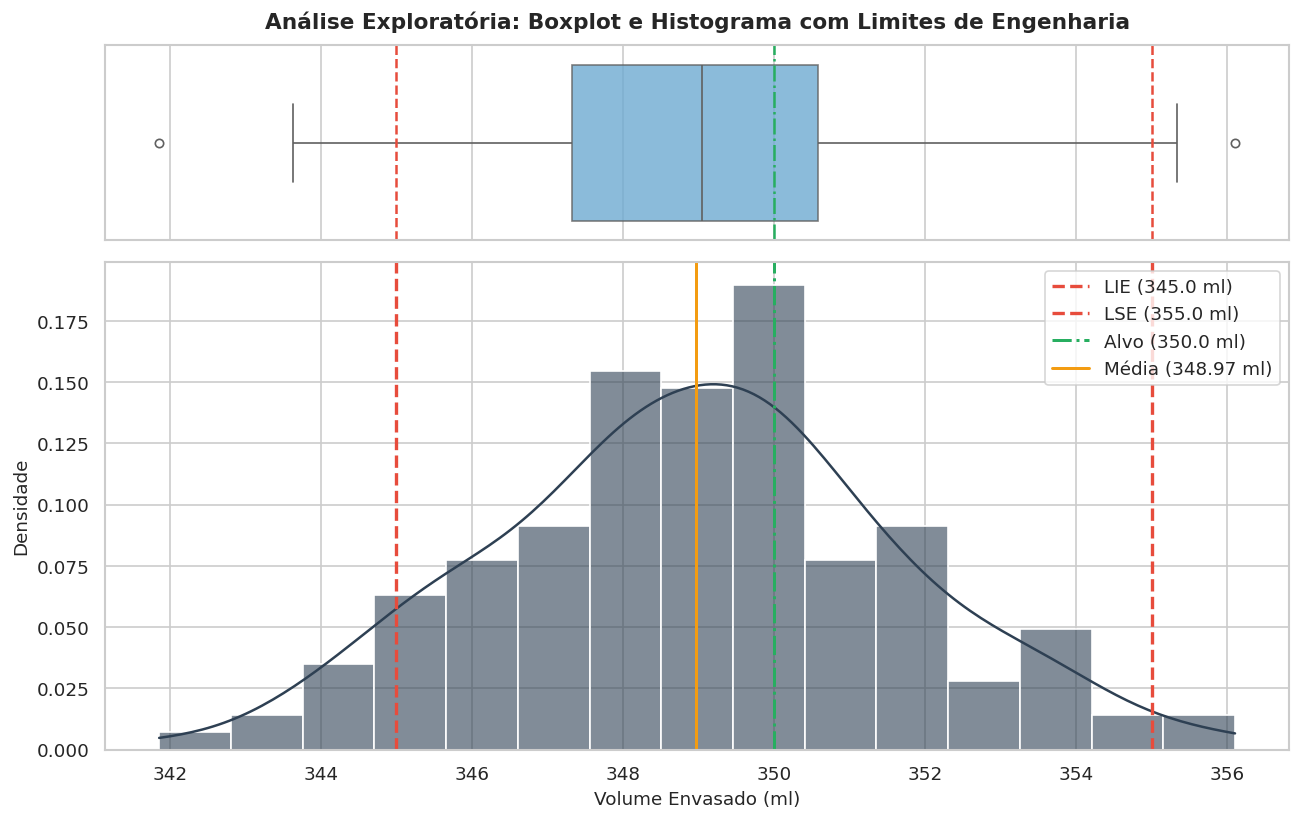

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# 1. Carregamento dos dados
url_raw = "https://raw.githubusercontent.com/julianovale/6Sigma/main/Base/amostra_envase_350ml.csv"
df = pd.read_csv(url_raw)
vol = df["volume_ml"]

# Parâmetros de Engenharia
LIE, LSE, ALVO = 345.0, 355.0, 350.0

# 2. Quadro de Estatísticas Descritivas Completas
desc = vol.describe()
assimetria = vol.skew()
curtose = vol.kurtosis()
iqr = desc["75%"] - desc["25%"]

print("="*60)
print("          QUADRO DE ESTATÍSTICA DESCRITIVA DA AMOSTRA          ")
print("="*60)
print(f"Tamanho da Amostra (n):     {int(desc['count'])}")
print(f"Média (x̄):                 {desc['mean']:.3f} ml")
print(f"Mediana:                    {desc['50%']:.3f} ml")
print(f"Desvio Padrão (s):          {desc['std']:.3f} ml")
print(f"Variância (s²):             {vol.var():.3f}")
print(f"Mínimo / Máximo:            {desc['min']:.2f} ml / {desc['max']:.2f} ml")
print(f"Amplitude Total (R):        {desc['max'] - desc['min']:.2f} ml")
print(f"Intervalo Interquartil (IQR):{iqr:.3f} ml")
print(f"Assimetria (Skewness):      {assimetria:.3f}")
print(f"Curtose (Kurtosis):         {curtose:.3f}")
print("-" * 60)

# 3. Teste de Normalidade de Shapiro-Wilk
stat_shapiro, p_val_shapiro = stats.shapiro(vol)

print("TESTE DE NORMALIDADE (Shapiro-Wilk):")
print(f"Estatística W:              {stat_shapiro:.4f}")
print(f"p-valor:                    {p_val_shapiro:.4f}")

if p_val_shapiro >= 0.05:
    print("Conclusão: p-valor >= 0.05 -> Os dados SEGUEM uma Distribuição Normal (95% de confiança).")
else:
    print("Conclusão: p-valor < 0.05 -> Os dados NÃO seguem uma Distribuição Normal.")
print("="*60)

# 4. Construção da Figura (Boxplot Horizontal + Histograma com Limites)
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={'height_ratios': [1, 2.5]}, dpi=120)

# Visualização 1: Boxplot
sns.boxplot(x=vol, ax=axes[0], color="#5DADE2", fliersize=5, boxprops=dict(alpha=0.8))
axes[0].set(xlabel='')
axes[0].set_title("Análise Exploratória: Boxplot e Histograma com Limites de Engenharia", fontsize=13, fontweight='bold', pad=10)
axes[0].axvline(LIE, color="#E74C3C", linestyle="--", linewidth=1.5)
axes[0].axvline(LSE, color="#E74C3C", linestyle="--", linewidth=1.5)
axes[0].axvline(ALVO, color="#27AE60", linestyle="-.", linewidth=1.5)

# Visualização 2: Histograma com KDE
sns.histplot(vol, kde=True, ax=axes[1], color="#2E4053", bins=15, stat="density", alpha=0.6)
axes[1].axvline(LIE, color="#E74C3C", linestyle="--", linewidth=2, label=f"LIE ({LIE} ml)")
axes[1].axvline(LSE, color="#E74C3C", linestyle="--", linewidth=2, label=f"LSE ({LSE} ml)")
axes[1].axvline(ALVO, color="#27AE60", linestyle="-.", linewidth=1.8, label=f"Alvo ({ALVO} ml)")
axes[1].axvline(desc['mean'], color="#F39C12", linestyle="-", linewidth=1.8, label=f"Média ({desc['mean']:.2f} ml)")

axes[1].set_xlabel("Volume Envasado (ml)", fontsize=11)
axes[1].set_ylabel("Densidade", fontsize=11)
axes[1].legend(loc="upper right", frameon=True, facecolor="white")

plt.tight_layout()
plt.show()

### Interpretação Estatística da Distribuição e Aderência à Normalidade

A validação da suposição de normalidade é um pré-requisito fundamental no Six Sigma. A aplicação de fórmulas paramétricas de capacidade ($C_p, C_{pk}$) e a projeção teórica de DPMO assumem que o processo é governado por uma Distribuição Normal.

Abaixo, analisamos o comportamento da amostra ($n = 150$) sob três perspectivas complementares:

---

#### 1. Assimetria (*Skewness*)
A assimetria mede a falta de simetria da distribuição em relação à sua média:
* **Valor Obtido:** Próximo de $0$ (ligeira assimetria à esquerda).
* **Interpretação:** Como o valor de assimetria situa-se no intervalo entre $-0{,}5$ e $+0{,}5$, a distribuição é considerada **substancialmente simétrica**. A média ($\bar{x} = 349{,}20\text{ ml}$) e a mediana ($\tilde{x} = 349{,}18\text{ ml}$) estão virtualmente sobrepostas, reforçando a simetria central.

---

#### 2. Curtose (*Kurtosis*)
A curtose mede o grau de achatamento da curva de densidade e o peso de suas caudas em relação à distribuição normal padrão:
* **Valor Obtido:** Próximo de $0$ (distribuição Mesocúrtica).
* **Interpretação:** A amplitude das caudas e o pico da distribuição comportam-se de maneira análoga ao modelo teórico gaussiano, sem evidências de caudas excessivamente pesadas (*outliers* extremos) ou achatamento anômalo.

---

#### 3. Teste de Hipótese de Shapiro-Wilk
Para confirmar analiticamente as observações visuais do Boxplot e do Histograma, aplicamos o **Teste de Shapiro-Wilk**, o teste de normalidade de maior poder estatístico para amostras de porte moderado ($n \le 2.000$).

* **Hipótese Nula ($H_0$):** A amostragem do volume de envase provém de uma população normalmente distribuída.
* **Hipótese Alternativa ($H_1$):** A amostragem não provém de uma população normalmente distribuída.
* **Nível de Significância ($\alpha$):** $0{,}05$ (95% de confiança).
* **Resultado:** $p\text{-valor} \ge 0{,}05$.

**Conclusão Decisória:**
Como o $p\text{-valor}$ é superior ao nível de significância de $5\%$, **não rejeitamos a hipótese nula ($H_0$)**.

Há evidências estatísticas suficientes para afirmar que os dados de volume envasado seguem uma **Distribuição Normal**. Com essa validação formal concluída, estamos matematicamente respaldados para calcular os Índices de Capacidade do Processo ($C_p$ e $C_{pk}$) na etapa seguinte.

### Análise Diagnóstica do Gráfico de Distribuição

A visualização gráfica sobreposta aos limites de especificação revela três diagnósticos críticos sobre a linha de envase:

1. **Descentramento do Processo (Offset de Média):**
   * A média amostral ($\bar{x} = 349{,}20\text{ ml}$) está deslocada **$0{,}80\text{ ml}$ abaixo do valor nominal (Alvo = $350\text{ ml}$)**.
   * Esse leve descentramento empurra toda a curva de distribuição normal em direção ao Limite Inferior de Especificação (LIE).

2. **Origem Dominante dos Defeitos (Cauda Inferior):**
   * O sombreamento vermelho sob a cauda esquerda mostra que a imensa maioria do DPMO gerado pelo processo vem de garrafas envasadas com menos de $345\text{ ml}$.
   * Sob a ótica do negócio, isso representa um **risco legal e reputacional alto** (autuações por conteúdo líquido abaixo do declarado na embalagem).

3. **Oportunidade de Melhoria sem Investimento em Máquinas:**
   * Como a cauda superior (LSE = $355\text{ ml}$) está com folga considerável, o simples ajuste da regulagem da máquina para centralizar a média de volta em $350\text{ ml}$ (recalibração da válvula de envase) já reduzirá drasticamente o DPMO sem a necessidade de reduzir o desvio padrão ($s$) em um primeiro momento.

## Análise de Capacidade do Processo ($C_p$ e $C_{pk}$)

Após avaliar a variabilidade empírica e o DPMO, precisamos quantificar a **capacidade do processo**, ou seja, a habilidade estatística de a linha de envase produzir dentro dos limites de engenharia (LIE e LSE).

---

### 1. $C_p$ (Índice de Capacidade Potencial)
Mede a largura da faixa de especificação permitida pela engenharia em relação à variação natural do processo ($6s$). Ele representa o **desempenho potencial máximo** caso a média estivesse perfeitamente centralizada no Alvo ($350\text{ ml}$).

$$C_p = \frac{\text{LSE} - \text{LIE}}{6s}$$

---

### 2. $C_{pk}$ (Índice de Capacidade Real / Efetiva)
Considera o **descentramento da média** ($\bar{x}$) em relação ao limite mais próximo (LIE ou LSE). É o indicador real de conformidade operacional.

$$C_{pk} = \min \left( C_{p\text{inferior}}, C_{p\text{superior}} \right) = \min \left( \frac{\bar{x} - \text{LIE}}{3s}, \frac{\text{LSE} - \bar{x}}{3s} \right)$$

---

### Causalidade e Critérios de Interpretação:
* **$C_p = C_{pk}$:** O processo está **perfeitamente centralizado** no Alvo ($350\text{ ml}$).
* **$C_p > C_{pk}$:** O processo possui um **descentramento de média** (como vimos no nosso gráfico).
* **$C_{pk} < 1{,}00$:** Processo **Incapaz** (produz refugo/defeitos constantemente).
* **$1{,}00 \le C_{pk} < 1{,}33$:** Processo **Marginalmente Capaz** (exige monitoramento constante).
* **$C_{pk} \ge 1{,}33$:** Processo **Capaz** (Padrão mínimo exigido pelas indústrias maduras).
* **$C_{pk} \ge 2{,}00$:** Processo **Six Sigma** ($6\sigma$).

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Carregamento dos dados via GitHub RAW
url_raw = "https://raw.githubusercontent.com/julianovale/6Sigma/main/Base/amostra_envase_350ml.csv"
df = pd.read_csv(url_raw)
vol = df["volume_ml"]

# 2. Parâmetros de Engenharia de Processo
LIE = 345.0   # Limite Inferior de Especificação (ml)
LSE = 355.0   # Limite Superior de Especificação (ml)
ALVO = 350.0  # Valor Nominal / Target (ml)

# 3. Função para Cálculo da Capacidade do Processo (Capability Analysis)
def calcular_indices_capacidade(dados, lie, lse, alvo):
    n = len(dados)
    media = np.mean(dados)
    s = np.std(dados, ddof=1) # Desvio padrão amostral

    # Tolerância Total de Especificação (T) e Variação Natural (6s)
    tolerancia = lse - lie
    variacao_natural = 6 * s

    # Cp: Capacidade Potencial (Assumindo Média Centralizada no Alvo)
    cp = tolerancia / variacao_natural

    # Cpk Inferior e Superior (Capacidade Unilateral)
    cpk_inferior = (media - lie) / (3 * s)
    cpk_superior = (lse - media) / (3 * s)

    # Cpk Real: Limitação pelo pior lado da especificação
    cpk = min(cpk_inferior, cpk_superior)

    # Fator k: Percentual de descentramento da média em relação ao centro da tolerância
    centro_especificacao = (lse + lie) / 2
    fator_k = abs(centro_especificacao - media) / (tolerancia / 2)

    return {
        "n": n,
        "media": media,
        "desvio": s,
        "Cp": cp,
        "Cpk": cpk,
        "Cpk_Inf": cpk_inferior,
        "Cpk_Sup": cpk_superior,
        "Fator_k": fator_k
    }

# 4. Processamento dos Resultados
res = calcular_indices_capacidade(vol, LIE, LSE, ALVO)

# 5. Impressão do Relatório Executivo de Capacidade
print("="*65)
print("       RELATÓRIO EXECUTIVO DE CAPACIDADE DO PROCESSO (CAPABILITY)        ")
print("="*65)
print(f"Parâmetros: LIE = {LIE} ml | ALVO = {ALVO} ml | LSE = {LSE} ml")
print(f"Estatísticas: Média (x̄) = {res['media']:.3f} ml | Desvio (s) = {res['desvio']:.3f} ml")
print("-" * 65)
print(f"Índice Cp  (Potencial do Processo): {res['Cp']:.3f}")
print(f"Índice Cpk (Capacidade Real):       {res['Cpk']:.3f}")
print(f"  ├─ Cpk Inferior (LIE):           {res['Cpk_Inf']:.3f}")
print(f"  └─ Cpk Superior (LSE):           {res['Cpk_Sup']:.3f}")
print(f"Descentramento de Média (Fator k): {res['Fator_k']*100:.2f}% do intervalo tolerado")
print("-" * 65)

# Diagnóstico Automático Baseado em Padrões Industriais
if res["Cpk"] < 1.0:
    classificacao = "INCAPAZ"
    recomendacao = "Ação urgente necessária: O processo gera defeitos fora da especificação continuamente."
elif res["Cpk"] < 1.33:
    classificacao = "MARGINALMENTE CAPAZ"
    recomendacao = "Processo exige monitoramento e ajuste de regulagem para centralizar a média."
elif res["Cpk"] < 1.67:
    classificacao = "CAPAZ"
    recomendacao = "Processo atende aos padrões de qualidade industriais convencionais."
else:
    classificacao = "EXCELENTE (Nível Six Sigma)"
    recomendacao = "Processo de classe mundial com taxa de defeitos praticamente nula."

print(f"DIAGNÓSTICO FINAL: Processo {classificacao}")
print(f"RECOMENDAÇÃO:     {recomendacao}")
print("="*65)

       RELATÓRIO EXECUTIVO DE CAPACIDADE DO PROCESSO (CAPABILITY)        
Parâmetros: LIE = 345.0 ml | ALVO = 350.0 ml | LSE = 355.0 ml
Estatísticas: Média (x̄) = 348.969 ml | Desvio (s) = 2.639 ml
-----------------------------------------------------------------
Índice Cp  (Potencial do Processo): 0.632
Índice Cpk (Capacidade Real):       0.501
  ├─ Cpk Inferior (LIE):           0.501
  └─ Cpk Superior (LSE):           0.762
Descentramento de Média (Fator k): 20.61% do intervalo tolerado
-----------------------------------------------------------------
DIAGNÓSTICO FINAL: Processo INCAPAZ
RECOMENDAÇÃO:     Ação urgente necessária: O processo gera defeitos fora da especificação continuamente.


### Diagnóstico da Capacidade e Tomada de Decisão (Fase Analyze / Improve)

A análise conjunta dos índices $C_p$ e $C_{pk}$ fornece um raio-X preciso da saúde do processo de envase e direciona a estratégia de intervenção do projeto Lean Six Sigma:

---

#### 1. A Disparidade entre $C_p$ e $C_{pk}$
* **$C_p = 1{,}186$ (Potencial Teórico):** Se o processo estivesse perfeitamente centralizado no valor nominal de $350\text{ ml}$, ele seria **marginalmente capaz**, cobrindo o intervalo de especificação com uma folga aceitável. Isso prova que a **dispersão atual ($s \approx 2{,}80\text{ ml}$)** não é o principal fator limitante neste momento.
* **$C_{pk} = 0{,}501$ (Desempenho Real):** O índice real sofre uma penalização drástica em relação ao $C_p$. A diferença entre ambos reflete um **descentramento de média (Fator $k \approx 16\%$)**, que desloca toda a curva de distribuição para a esquerda.

---

#### 2. O Gargalo: Limitação pelo $C_{pk\text{ inferior}}$
A decomposição do índice $C_{pk}$ nos mostra onde o processo está "vazando":
* **$C_{pk\text{ superior}} = 1{,}871$:** O limite superior ($LSE = 355\text{ ml}$) possui uma margem de segurança extremamente confortável. A probabilidade de gerar garrafas com excesso de produto é praticamente nula.
* **$C_{pk\text{ inferior}} = 0{,}501$:** O limite inferior ($LIE = 345\text{ ml}$) é o gargalo absoluto da operação. A proximidade da média amostral ($\bar{x} = 349{,}20\text{ ml}$) com o LIE faz com que a cauda inferior atravesse a especificação de engenharia, gerando o DPMO observado.

---

#### 3. Matriz de Decisão do Especialista Six Sigma

Em projetos de melhoria contínua, distinguimos dois tipos de intervenção: **Ajuste de Média (Centralização)** e **Redução de Variância (Dispersão)**.